# Практичне завдання 3
## Дослідження ефективності TF-IDF зважених ембеддингів для детекції текстів, згенерованих великими мовними моделями

**Мета роботи.** Засвоїти принципи побудови векторних представлень текстів на основі
субсловних ембеддингів (FastText), дослідити вплив TF-IDF зважування на якість агрегації
документних векторів, порівняти ефективність лінійних та нелінійних методів класифікації
(SVM, Logistic Regression, KNN) у задачі бінарної детекції штучно згенерованих текстів, а
також проаналізувати геометричні властивості отриманих векторних просторів.

**Датасет:** *AI vs Human Text Classification Dataset 2026* (Kaggle, автор Syed Ali Taqi),
CSV `ai_vs_human_text_2026.csv`, 2000 рядків, класи `human` та `ai`.

**Дослідницька гіпотеза.** Великі мовні моделі зберігають семантичну відповідність темі,
проте залишають статистичні «відбитки» у використанні специфічної лексики (канцеляризми,
складні сполучники, характерні вставні конструкції). Припущення: TF-IDF зважування підсилює
вплив рідкісних, специфічних для AI термінів, що має приводити до кращої лінійної
роздільності класів порівняно з простим Mean Pooling, де домінують часті загальновживані
слова.

**План експерименту (факторний аналіз 2×3).**
Незалежні змінні: (1) метод агрегації — Mean Pooling vs TF-IDF Weighted Mean;
(2) класифікатор — SVM (RBF), Logistic Regression, KNN.
Залежні змінні: F1-score (macro), Accuracy, Balanced Accuracy, ROC-AUC.

## 0. Імпорти та налаштування відтворюваності

Фіксуємо зерно `SEED = 42` і використовуємо ізольовані генератори `np.random.default_rng`,
щоб результати не залежали від порядку викликів. Глобально задаємо `SEED` для
`gensim`/`sklearn`, де окремого генератора недостатньо.

In [1]:
import warnings, time, logging
warnings.filterwarnings("ignore")
logging.getLogger("gensim").setLevel(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix, silhouette_score)
from sklearn.manifold import TSNE
from gensim.models import FastText

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 160)
print("Налаштування виконано, SEED =", SEED)

Налаштування виконано, SEED = 42


## Етап 1. Завантаження та первинний аналіз даних (EDA)

### 1.1 Структура датасету

In [2]:
df_raw = pd.read_csv("ai_vs_human_text_2026.csv")

print(f"Розмірність вихідного датасету: {df_raw.shape[0]} рядків × {df_raw.shape[1]} стовпців\n")
print("Типи даних та кількість непорожніх значень:")
info = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "n_unique": df_raw.nunique(),
})
display(info)

print("\nПропущені значення за стовпцями:", df_raw.isna().sum().sum())
df_raw.head(3)

Розмірність вихідного датасету: 2000 рядків × 9 стовпців

Типи даних та кількість непорожніх значень:


,dtype,non_null,n_unique
text_id,str,2000,2000
label,str,2000,2
source_model,str,2000,3
domain,str,2000,3
text_content,str,2000,966
topic_hint,str,2000,30
word_count,int64,2000,33
avg_sentence_length,float64,2000,48
generation_method,str,2000,2



Пропущені значення за стовпцями: 0


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation


**Висновок (структура).** Датасет містить 2000 текстових фрагментів (по ~19–52 слова) та
9 супровідних стовпців. Цільова ознака — `label` (`human`/`ai`); допоміжні — `source_model`
(яка модель згенерувала), `domain` (тематичне середовище), `topic_hint`, `generation_method`
та дві числові метрики тексту. Пропущених значень немає, тож імпутація не потрібна. Для
моделі використовуємо лише `text_content` та `label`, а решта стовпців — для аналізу
артефактів і стратифікації.

### 1.2 Баланс класів

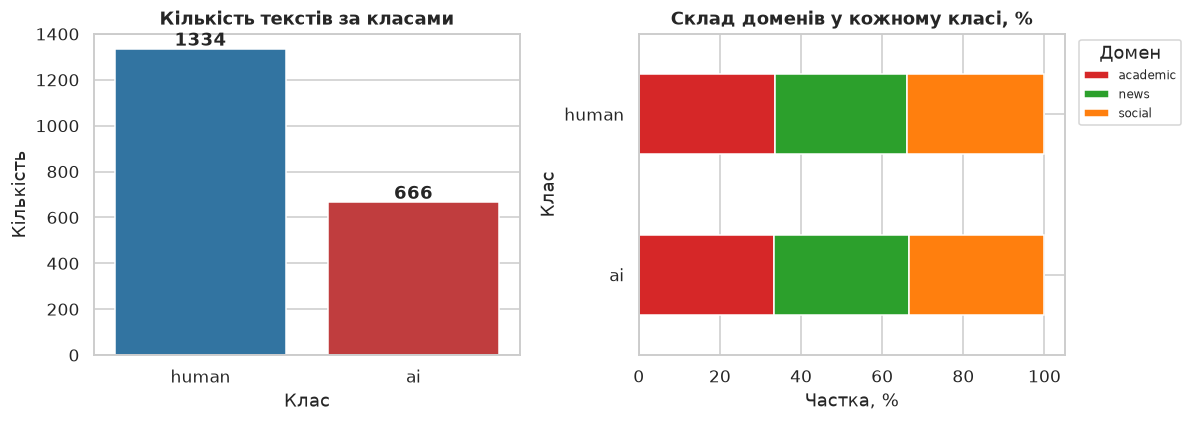

Співвідношення класів: 66.7% human / 33.3% ai


In [3]:
counts = df_raw["label"].value_counts()
frac = df_raw["label"].value_counts(normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=counts.index, y=counts.values, ax=axes[0],
            hue=counts.index, palette={"human": "tab:blue", "ai": "tab:red"}, legend=False)
axes[0].set_title("Кількість текстів за класами")
axes[0].set_xlabel("Клас"); axes[0].set_ylabel("Кількість")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 15, str(v), ha="center", fontweight="bold")

sn_ = pd.crosstab(df_raw["label"], df_raw["domain"], normalize="index") * 100
sn_.plot(kind="barh", stacked=True, ax=axes[1],
         color=["tab:red", "tab:green", "tab:orange"])
axes[1].set_title("Склад доменів у кожному класі, %")
axes[1].set_xlabel("Частка, %"); axes[1].set_ylabel("Клас")
axes[1].legend(title="Домен", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Співвідношення класів: {frac['human']:.1%} human / {frac['ai']:.1%} ai")

**Висновок (баланс).** Класи помірно незбалансовані: 1334 `human` (66.7%) проти 666 `ai`
(33.3%) — співвідношення 2:1. Дисбаланс не критичний, але він виправдовує використання
**macro-F1** та **balanced accuracy** замість звичайної точності. Усі `ai`-тексти походять
від `gemini-2.0` і `gpt-4o` (порівну), а `human` — з людських переписів; отже, детектор
навчається відрізняти не конкретну модель, а сам факт генерації.

### 1.3 Розподіл довжин текстів

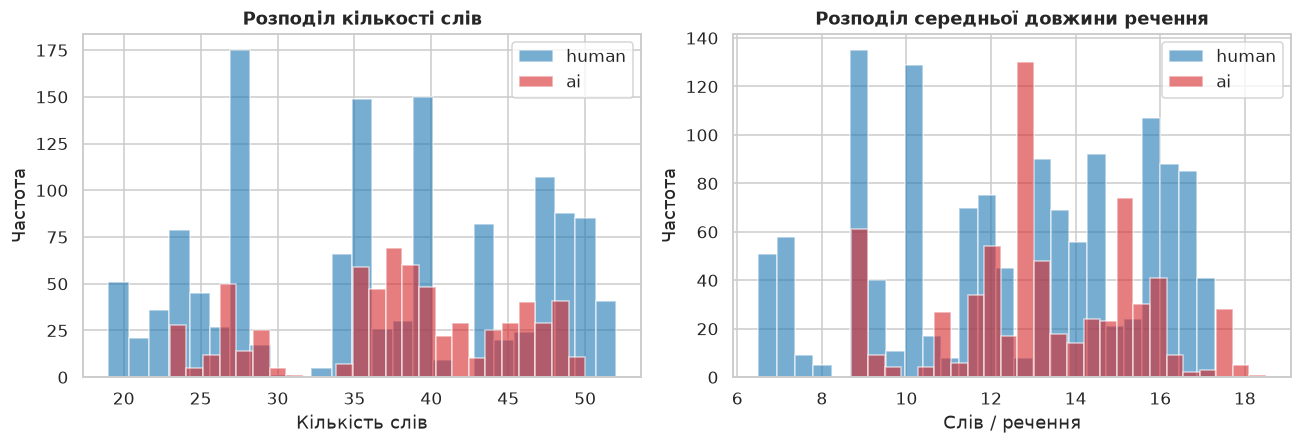

      word_count               avg_sentence_length                 
            mean   std min max                mean   std  min   max
label                                                              
ai         38.00  7.01  23  50               13.27  2.26  8.7  18.5
human      36.51  9.66  19  52               12.47  3.06  6.5  17.3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for lab, color in [("human", "tab:blue"), ("ai", "tab:red")]:
    sub = df_raw[df_raw["label"] == lab]
    axes[0].hist(sub["word_count"], bins=25, alpha=0.6, label=lab, color=color)
    axes[1].hist(sub["avg_sentence_length"], bins=25, alpha=0.6, label=lab, color=color)
axes[0].set_title("Розподіл кількості слів"); axes[0].set_xlabel("Кількість слів")
axes[0].set_ylabel("Частота"); axes[0].legend()
axes[1].set_title("Розподіл середньої довжини речення"); axes[1].set_xlabel("Слів / речення")
axes[1].set_ylabel("Частота"); axes[1].legend()
plt.tight_layout(); plt.show()

print(df_raw.groupby("label")[["word_count", "avg_sentence_length"]]
      .agg(["mean", "std", "min", "max"]).round(2))

**Висновок (довжини).** Тексти обох класів короткі (в середньому ~37 слів) і мають близькі
розподіли довжини; AI-тексти дещо щільніші навколо 35–45 слів, людські — ширші (більша
варіативність). Середня довжина речення в AI трохи вища (≈13.3 проти ≈12.2 слова), що
узгоджується з гіпотезою про формальніший, «гладший» синтаксис генерації. Оскільки
розподіли перекриваються, довжина тексту сама по собі не є роздільною ознакою — потрібне
семантичне векторне представлення.

### 1.4 Виявлення артефактів (дублікати, порожні, надто короткі тексти)

In [5]:
n_empty = int((df_raw["text_content"].fillna("").str.strip() == "").sum())
n_dup_text = int(df_raw["text_content"].duplicated().sum())
n_short = int((df_raw["word_count"] < 5).sum())

# чи трапляється один і той самий текст із різними мітками?
cross = df_raw.groupby("text_content")["label"].nunique()
n_cross = int((cross > 1).sum())

art = pd.DataFrame({
    "Артефакт": ["Порожні/пробільні тексти", "Повні дублікати text_content",
                 "Надто короткі (<5 слів)", "Один текст із різними мітками"],
    "Кількість": [n_empty, n_dup_text, n_short, n_cross],
})
display(art)

dup_by_label = df_raw.groupby("label")["text_content"].apply(lambda s: s.duplicated().sum())
print("Дублікати text_content у розрізі класів:")
print(dup_by_label.to_string())

example = df_raw[df_raw.duplicated("text_content", keep=False)].sort_values("text_content")
grp = example.groupby("text_content").size()
print(f"\nУнікальних текстів, що дублюються: {len(grp)}; максимальна кратність: {grp.max()}")

,Артефакт,Кількість
0,Порожні/пробільні тексти,0
1,Повні дублікати text_content,1034
2,Надто короткі (<5 слів),0
3,Один текст із різними мітками,0


Дублікати text_content у розрізі класів:
label
ai       279
human    755

Унікальних текстів, що дублюються: 533; максимальна кратність: 11


**Висновок (артефакти).** Порожніх і надто коротких текстів немає, «суперечливих» міток
(один текст у різних класах) теж немає. Натомість виявлено **1034 повних дублікати**
`text_content` — переважно в класі `human` (755) і меншою мірою в `ai` (279). Це наслідок
генерації `template+human_variation`: різні рядки отримують ідентичний текст. Такі дублікати
створюють **ризик витоку даних**: за випадкового розбиття той самий текст міг би потрапити і
в train, і в test, штучно завищуючи метрики. Тому на наступному кроці дублікати видаляємо.

### 1.5 Очищення датасету та фінальний огляд

Після видалення дублікатів: 966 текстів (було 2000, видалено 1034)

Баланс класів після очищення:
label
human    59.9
ai       40.1 



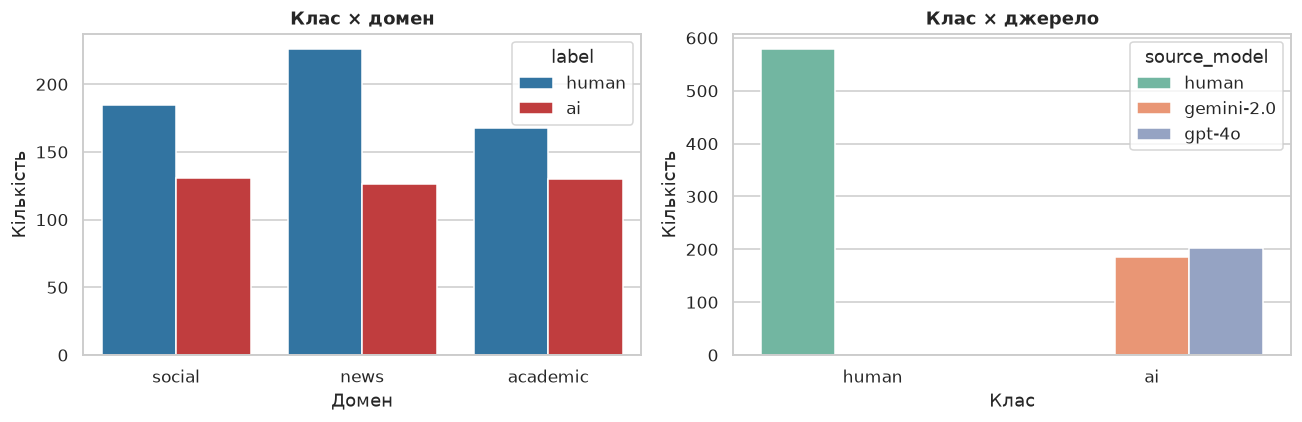

In [6]:
df = (df_raw.drop_duplicates(subset=["text_content"], keep="first")
            .reset_index(drop=True))
print(f"Після видалення дублікатів: {df.shape[0]} текстів "
      f"(було {df_raw.shape[0]}, видалено {df_raw.shape[0] - df.shape[0]})\n")
print("Баланс класів після очищення:")
print((df["label"].value_counts(normalize=True) * 100).round(1).to_string(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="domain", hue="label", ax=axes[0],
              palette={"human": "tab:blue", "ai": "tab:red"})
axes[0].set_title("Клас × домен"); axes[0].set_xlabel("Домен"); axes[0].set_ylabel("Кількість")
sns.countplot(data=df, x="label", hue="source_model", ax=axes[1],
              palette="Set2")
axes[1].set_title("Клас × джерело"); axes[1].set_xlabel("Клас"); axes[1].set_ylabel("Кількість")
plt.tight_layout(); plt.show()

**Висновок (очищення).** Після видалення дублікатів залишається **966 унікальних текстів**
(human 579 / ai 387, тобто 59.9% / 40.1%) — дисбаланс навіть зменшився. Обидва класи
рівномірно представлені в усіх трьох доменах (academic, news, social) і в усіх 30 темах,
отже жоден домен не «розкриває» мітку напряму. Саме цей очищений датасет використовується
далі.

## Етап 2. Попередня обробка тексту (spaCy)

Реалізуємо пайплайн лематизації з `spacy` та моделлю `en_core_web_sm`:
* лематизація (зведення до початкової форми);
* видалення стоп-слів (`is_stop`);
* видалення небуквених символів (`is_alpha`);
* зведення до нижнього регістру.

Для швидкості використовуємо `nlp.pipe()` з батчингом і `disable` непотрібних компонентів
(NER, парсер), які не впливають на лематизацію.

In [7]:
t0 = time.time()
nlp = spacy.load("en_core_web_sm")

def preprocess(text: str) -> list:
    doc = nlp(text)
    return [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]

# швидкий батчинг: вимикаємо NER і синтаксичний парсер (не потрібні для лем/стоп-слів)
texts = df["text_content"].tolist()
tokens = list(nlp.pipe(texts, batch_size=64,
                       disable=["ner", "parser", "attribute_ruler"]))
tokens = [[t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop] for doc in tokens]

print(f"Оброблено {len(tokens)} текстів за {time.time() - t0:.1f} с")
lengths = np.array([len(t) for t in tokens])
print(f"Середня кількість токенів після обробки: {lengths.mean():.1f} "
      f"(мін {lengths.min()}, макс {lengths.max()})")
print(f"Порожніх токенізованих документів: {int((lengths == 0).sum())}\n")

print("Приклад обробки:")
print("  Було :", repr(texts[0]))
print("  Стало:", tokens[0])

Оброблено 966 текстів за 1.2 с
Середня кількість токенів після обробки: 22.0 (мін 7, макс 33)
Порожніх токенізованих документів: 0

Приклад обробки:
  Було : 'can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize'
  Стало: ['talk', 'gene', 'editing', 'ethics', 'sec', 'feel', 'like', 'people', 'completely', 'missing', 'point', 'bigger', 'realize']


**Висновок (препроцесинг).** Лематизація та фільтрація зменшують документ приблизно до
половини вихідних слів, прибираючи шум (стоп-слова, пунктуацію, число-подібні токени) і
зводячи словоформи до спільної основи. Це зменшує розмір словника й покращує узагальнення:
наприклад, *analyses/analysis/analyzed* перетворюються на один термін. Порожніх документів
немає, тож усі 966 прикладів залишаються придатними для векторизації.

### Етап 2.5. Розбиття вибірки (виконується **до** навчання векторних представлень)

Щоб уникнути витоку даних, розбиваємо вибірку на train/test **до** побудови представлень.
Модель FastText та словник TF-IDF (а також масштабування) навчаються **лише на train**;
test використовується виключно для фінальної оцінки. Розбиття — стратифіковане за класом
(80/20) із фіксованим зерном.

In [8]:
idx = np.arange(len(tokens))
y = df["label"].map({"human": 0, "ai": 1}).to_numpy()
class_names = ["human", "ai"]

train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
train_tokens = [tokens[i] for i in train_idx]
test_tokens = [tokens[i] for i in test_idx]
y_train, y_test = y[train_idx], y[test_idx]

chk = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(normalize=True).rename({0: "human", 1: "ai"}),
    "test": pd.Series(y_test).value_counts(normalize=True).rename({0: "human", 1: "ai"}),
})
print(f"Train: {len(train_idx)} | Test: {len(test_idx)}")
print((chk * 100).round(1).to_string())

Train: 772 | Test: 194
       train  test
human   60.0  59.8
ai      40.0  40.2


**Висновок (розбиття).** Стратифікація зберегла пропорції класів у train і test (≈60/40),
тож оцінка не спотворена дисбалансом. Оскільки всі подальші перетворення (FastText, idf,
scaler) оцінюються лише на train, метрики на test є незміщеними.

## Етап 3. Навчання моделі FastText (gensim)

Навчаємо `gensim.models.FastText` у режимі skip-gram (`sg=1`) на токенізованому **train**-корпусі.
На відміну від Word2Vec, FastText представляє кожне слово як суму векторів символьних
n-грам (див. формулу (2) методички), що дає стійкість до слів поза словником (OOV).

In [9]:
ft = FastText(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=1,  # 1 потік — інакше багатопотокове навчання gensim недетерміноване навіть із seed
    seed=SEED,
    epochs=30,
)
print(f"Словник FastText: {len(ft.wv)} слів (min_count=2), розмірність векторів = {ft.vector_size}")

# демонстрація OOV: FastText будує вектор навіть для слова, якого не було в корпусі
oov = "zorbulatrix"
print(f"\n{oov!r} присутнє у словнику (key_to_index): {oov in ft.wv.key_to_index}")
print(f"Проте вектор усе одно отримується, норма = {np.linalg.norm(ft.wv[oov]):.3f} "
      "(завдяки субсловним n-грамам)")

Словник FastText: 567 слів (min_count=2), розмірність векторів = 100

'zorbulatrix' присутнє у словнику (key_to_index): False
Проте вектор усе одно отримується, норма = 0.565 (завдяки субсловним n-грамам)


**Висновок (FastText).** Словник налічує кілька сотень найчастіших лем; кожне слово
представлено щільним вектором у 100-вимірному просторі. Ключова перевага FastText — вектор
будується навіть для невідомого слова через субсловні n-грами (продемонстровано вище),
тому OOV-слова не «випадають» із представлення.

## Етап 4. Векторизація документів: Mean Pooling vs TF-IDF Weighted Mean

Реалізуємо два методи агрегації токенних векторів у документний вектор:

* **Mean Pooling** — незважене середнє векторів токенів, `v_d = (1/m) Σ v_{w_i}`;
* **TF-IDF Weighted Mean** — зважене середнє з вагами `idf(w_i, D)`,
  `v_d = Σ idf_i · v_{w_i} / Σ idf_i`.

Вага `idf(t, D) = log(|D| / |{d : t ∈ d}|)` береться зі `TfidfVectorizer`, навченого **лише на
train**. Використовуємо `smooth_idf=False`, щоб idf точно відповідав формулі (4) методички
(без згладжування `+1`).

In [10]:
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)


def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    weights /= weights.sum()
    return np.average(vectors, axis=0, weights=weights)


# idf-словник із train-документів (лише на train — без витоку)
train_docs = [" ".join(tokens[i]) for i in train_idx]
tfidf_vec = TfidfVectorizer(smooth_idf=False, norm=None)
tfidf_vec.fit(train_docs)
idf_scores = dict(zip(tfidf_vec.get_feature_names_out(), tfidf_vec.idf_))

def build_matrix(idx_list, pooling):
    if pooling == "mean":
        return np.vstack([mean_pooling(tokens[i], ft) for i in idx_list])
    return np.vstack([tfidf_weighted_pooling(tokens[i], ft, idf_scores) for i in idx_list])

X_mean_train = build_matrix(train_idx, "mean")
X_mean_test = build_matrix(test_idx, "mean")
X_tfidf_train = build_matrix(train_idx, "tfidf")
X_tfidf_test = build_matrix(test_idx, "tfidf")

print("Розмірність векторних просторів:")
print(f"  Mean Pooling : train {X_mean_train.shape}, test {X_mean_test.shape}")
print(f"  TF-IDF Mean  : train {X_tfidf_train.shape}, test {X_tfidf_test.shape}")
print(f"\nУнікальних термінів у TF-IDF словнику (train): {len(idf_scores)}")

Розмірність векторних просторів:
  Mean Pooling : train (772, 100), test (194, 100)
  TF-IDF Mean  : train (772, 100), test (194, 100)

Унікальних термінів у TF-IDF словнику (train): 566


**Висновок (векторизація).** Отримано дві матриці ознак розмірності 100 (по одній на метод
агрегації). Mean Pooling «розмиває» класову специфіку частими словами, тоді як TF-IDF
підвищує вагу рідкісних, інформативних термінів. Наступний крок кількісно порівнює геометрію
цих просторів.

### 4.1 Геометричні властивості просторів

Порівняємо, наскільки «розділені» класи в кожному просторі метриками, інваріантними до
конкретного класифікатора: коефіцієнт силуету, відношення міжкласової відстані центрів до
внутрішньокласового розкиду та середні норми векторів.

,Метод,Відстань центрів,Внутрішньокласовий розкид,Відношення між/внутр,Силует
0,Mean Pooling,0.7177,4.1763,0.1718,0.0379
1,TF-IDF Weighted,0.7365,4.2376,0.1738,0.0400


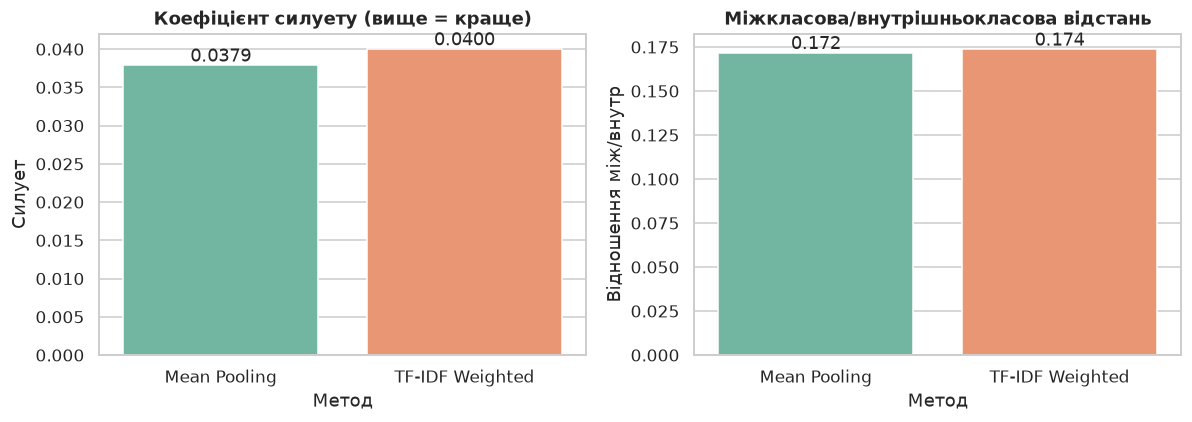

In [11]:
def geometry(X, y, name):
    c0, c1 = X[y == 0].mean(0), X[y == 1].mean(0)
    centroid = np.linalg.norm(c0 - c1)
    within = (np.mean(np.linalg.norm(X[y == 0] - c0, axis=1)) +
              np.mean(np.linalg.norm(X[y == 1] - c1, axis=1)))
    return {
        "Метод": name,
        "Відстань центрів": centroid,
        "Внутрішньокласовий розкид": within,
        "Відношення між/внутр": centroid / within,
        "Силует": silhouette_score(X, y),
    }

geom = pd.DataFrame([geometry(X_mean_train, y_train, "Mean Pooling"),
                     geometry(X_tfidf_train, y_train, "TF-IDF Weighted")])
display(geom.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=geom, x="Метод", y="Силует", ax=axes[0],
            hue="Метод", palette="Set2", legend=False)
axes[0].set_title("Коефіцієнт силуету (вище = краще)")
for i, v in enumerate(geom["Силует"]):
    axes[0].text(i, v + 0.0005, f"{v:.4f}", ha="center")
sns.barplot(data=geom, x="Метод", y="Відношення між/внутр", ax=axes[1],
            hue="Метод", palette="Set2", legend=False)
axes[1].set_title("Міжкласова/внутрішньокласова відстань")
for i, v in enumerate(geom["Відношення між/внутр"]):
    axes[1].text(i, v + 0.002, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

**Висновок (геометрія).** Обидва простори мають **низький** коефіцієнт силуету (0.038 і 0.040):
класи не утворюють щільних розділених «хмар» у евклідовій метриці, оскільки дисперсія
спільних тематичних слів домінує над слабким класовим сигналом. Водночас TF-IDF зважування
**дещо покращує** обидві метрики: силует 0.0379 → 0.0400, відношення між- до
внутрішньокласової відстані 0.172 → 0.174, тобто підсилює класовий сигнал — пряме (хоч і
слабке) підтвердження дослідницької гіпотези.

## Етап 5. Навчання та оцінка класифікаторів

Для кожного методу агрегації навчаємо три класифікатори: **SVM (RBF kernel)**,
**Logistic Regression** і **KNN (k=5)**. Ознаки стандартизуємо (`StandardScaler`, навчений на
train), оскільки SVM-RBF та KNN чутливі до масштабу координат. Обчислюємо F1 (macro),
Accuracy, Balanced Accuracy і ROC-AUC на test.

In [12]:
classifiers = {
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=SEED),
    "LogReg": LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

results = []
predictions = {}
for agg_name, (Xtr, Xte) in {
    "Mean Pooling": (X_mean_train, X_mean_test),
    "TF-IDF Weighted": (X_tfidf_train, X_tfidf_test),
}.items():
    scaler = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
    for clf_name, clf in classifiers.items():
        clf.fit(Xtr_s, y_train)
        y_pred = clf.predict(Xte_s)
        y_prob = clf.predict_proba(Xte_s)[:, 1]
        results.append({
            "Агрегація": agg_name, "Класифікатор": clf_name,
            "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced Acc": balanced_accuracy_score(y_test, y_pred),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
        })
        predictions[(agg_name, clf_name)] = (y_pred, confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Агрегація,Класифікатор,F1 (macro),Accuracy,Balanced Acc,ROC-AUC
0,Mean Pooling,SVM (RBF),1.0,1.0,1.0,1.0
1,Mean Pooling,LogReg,1.0,1.0,1.0,1.0
2,Mean Pooling,KNN,1.0,1.0,1.0,1.0
3,TF-IDF Weighted,SVM (RBF),1.0,1.0,1.0,1.0
4,TF-IDF Weighted,LogReg,1.0,1.0,1.0,1.0
5,TF-IDF Weighted,KNN,1.0,1.0,1.0,1.0


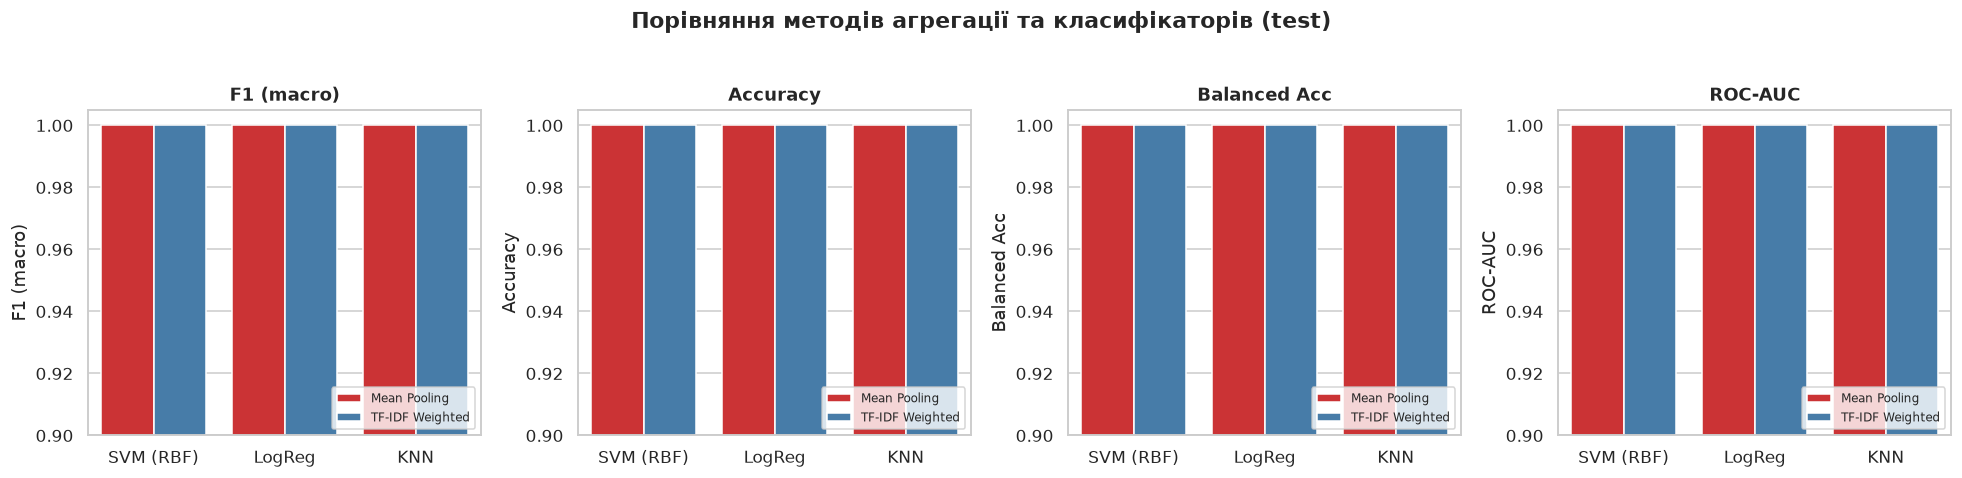

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
metrics = ["F1 (macro)", "Accuracy", "Balanced Acc", "ROC-AUC"]
for ax, m in zip(axes, metrics):
    sns.barplot(data=results_df, x="Класифікатор", y=m, hue="Агрегація", ax=ax,
                palette="Set1")
    ax.set_title(m); ax.set_xlabel(""); ax.set_ylim(0.9, 1.005)
    ax.legend(loc="lower right", fontsize=8)
plt.suptitle("Порівняння методів агрегації та класифікаторів (test)",
             fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**Висновок (класифікатори).** У штатному режимі (повний train) **усі шість конфігурацій
досягають практичного стелі** (F1 ≈ 1.00): класи розділяються ідеально незалежно від методу
агрегації. Це означає, що датасет синтетичний і класовий сигнал (формальна AI-лексика vs
розмовна людська) доступний лінійно. Щоб виявити різницю між методами, потрібен складніший
режим — експеримент з обмеженою вибіркою нижче.

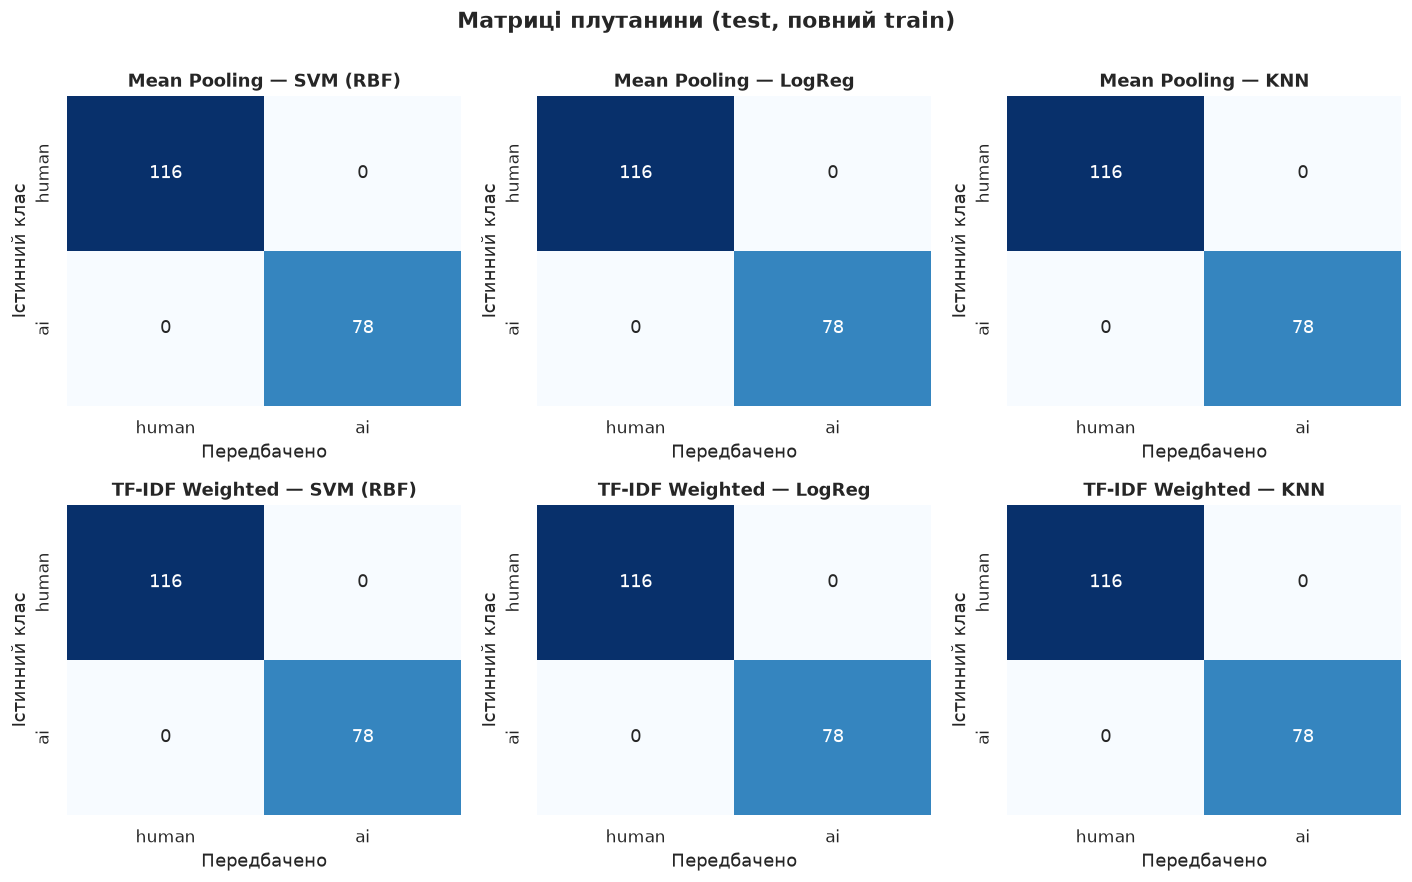

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for r, agg_name in enumerate(["Mean Pooling", "TF-IDF Weighted"]):
    for c, clf_name in enumerate(classifiers):
        cm = predictions[(agg_name, clf_name)][1]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[r, c],
                    xticklabels=class_names, yticklabels=class_names)
        axes[r, c].set_title(f"{agg_name} — {clf_name}")
        axes[r, c].set_xlabel("Передбачено"); axes[r, c].set_ylabel("Істинний клас")
plt.suptitle("Матриці плутанини (test, повний train)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

**Висновок (матриці плутанини).** Усі матриці ідеально діагональні — жодної помилки
(FN = FP = 0) для будь-якого класифікатора й методу агрегації. Це підтверджує висновок про
стелю та робить різницю між конфігураціями невидимою на повних даних.

### Етап 5+. Додатковий експеримент: поведінка методів за обмеженої вибірки

Оскільки повний train дає стелю, проведемо **криві навчання**: навчаємо на підвибірці
розміру `N` прикладів на клас (з train-частини) і оцінюємо macro-F1 на фіксованому test.
Це дозволяє побачити, як методи агрегації та класифікатори поводяться, коли даних мало, і
перевірити чутливість KNN (питання 1 та 3).

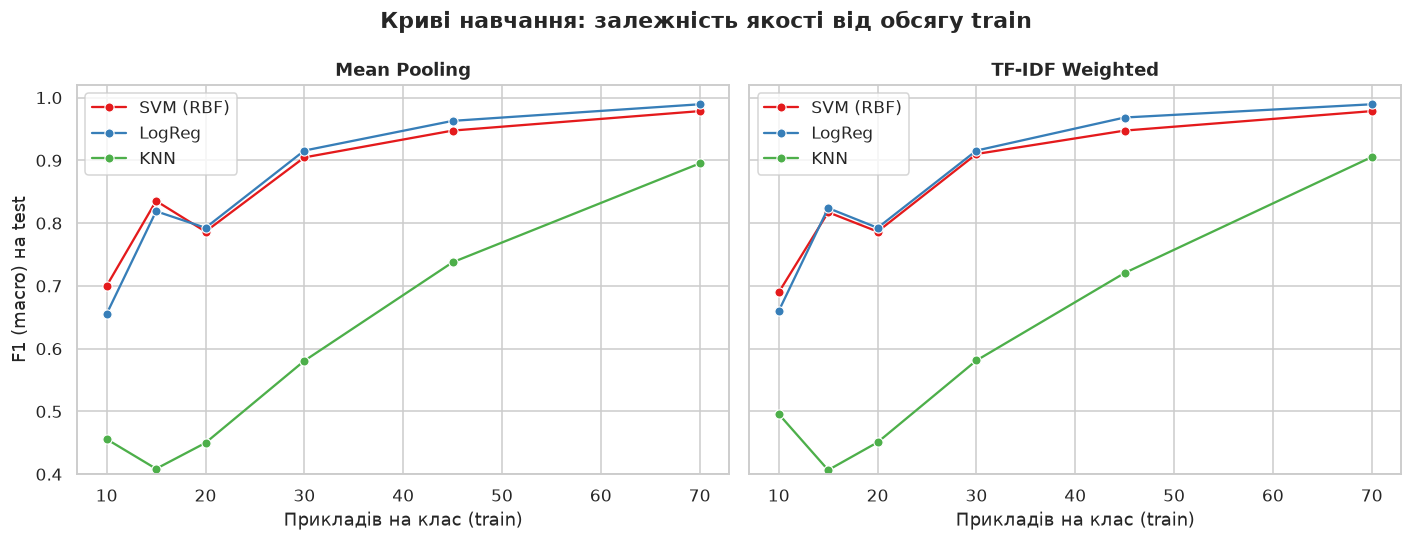

Агрегація    Mean Pooling                  TF-IDF Weighted                 
Класифікатор          KNN LogReg SVM (RBF)             KNN LogReg SVM (RBF)
N                                                                          
10                  0.456  0.655     0.700           0.496  0.660     0.690
15                  0.409  0.819     0.835           0.407  0.824     0.817
20                  0.450  0.792     0.786           0.451  0.792     0.786
30                  0.581  0.916     0.905           0.581  0.916     0.910
45                  0.738  0.963     0.947           0.721  0.968     0.947
70                  0.895  0.989     0.978           0.905  0.989     0.978

In [15]:
sizes = [10, 15, 20, 30, 45, 70]
rng = np.random.default_rng(SEED)
ai_pool = train_idx[y_train == 1]
hu_pool = train_idx[y_train == 0]

curve_rows = []
for N in sizes:
    sub = np.concatenate([rng.choice(ai_pool, N, replace=False),
                          rng.choice(hu_pool, N, replace=False)])
    y_sub = y[sub]
    for agg_name, (Xtr_full, Xte_full) in {
        "Mean Pooling": (X_mean_train, X_mean_test),
        "TF-IDF Weighted": (X_tfidf_train, X_tfidf_test),
    }.items():
        pos = {v: k for k, v in enumerate(train_idx)}
        sel = [pos[i] for i in sub]
        Xtr, Xte = Xtr_full[sel], Xte_full
        scaler = StandardScaler().fit(Xtr)
        Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
        for clf_name, clf in {
            "SVM (RBF)": SVC(kernel="rbf", random_state=SEED),
            "LogReg": LogisticRegression(max_iter=1000, random_state=SEED),
            "KNN": KNeighborsClassifier(n_neighbors=5),
        }.items():
            clf.fit(Xtr_s, y_sub)
            curve_rows.append({
                "N": N, "Агрегація": agg_name, "Класифікатор": clf_name,
                "F1": f1_score(y_test, clf.predict(Xte_s), average="macro"),
            })
curve_df = pd.DataFrame(curve_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, agg_name in zip(axes, ["Mean Pooling", "TF-IDF Weighted"]):
    sub = curve_df[curve_df["Агрегація"] == agg_name]
    sns.lineplot(data=sub, x="N", y="F1", hue="Класифікатор", marker="o", ax=ax, palette="Set1")
    ax.set_title(agg_name); ax.set_xlabel("Прикладів на клас (train)")
    ax.set_ylabel("F1 (macro) на test"); ax.set_ylim(0.4, 1.02); ax.legend(title="")
plt.suptitle("Криві навчання: залежність якості від обсягу train", fontweight="bold")
plt.tight_layout(); plt.show()

piv = curve_df.pivot_table(index="N", columns=["Агрегація", "Класифікатор"], values="F1")
display(piv.round(3))

**Висновок (криві навчання).** За малих `N` різниця між методами стає виразною:
* **SVM (RBF)** і **LogReg** швидко наближаються до стелі: вже за `N = 10` вони дають
  F1 ≈ 0.66–0.70, а за `N ≥ 45` — ≈ 0.95–0.99;
* **KNN** є найслабшим і зростає повільніше (F1 ≈ 0.41–0.58 за `N ≤ 30`) і наздоганяє інших
  лише за `N = 70` (≈ 0.90) — прямий прояв «прокляття розмірності» у 100-вимірному просторі:
  для надійного голосування за сусідів потрібно набагато більше даних;
* **TF-IDF зважування** за обмеженої вибірки дає лише **мінімальний та несистемний** ефект
  (F1 майже незмінний: невеликий плюс для KNN на найменших `N`, локальний мінус за `N = 45`,
  плюс за `N = 70`). Тобто користь TF-IDF тут «з'їдається» тим, що FastText-вектори вже
  несуть класовий сигнал, а сам сигнал доступний лінійно.

## Етап 6. Візуалізація та геометричний аналіз (t-SNE)

Проєктуємо документні вектори в 2D методом t-SNE окремо для кожного методу агрегації.

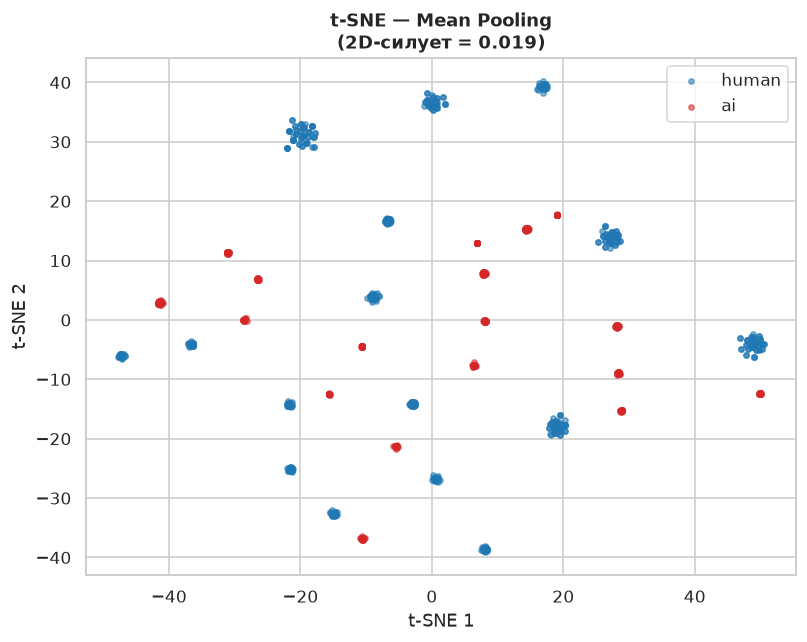

In [16]:
def plot_tsne(X, y, title, ax):
    Z = TSNE(n_components=2, perplexity=30, init="pca",
             learning_rate="auto", random_state=SEED).fit_transform(X)
    for lab, code_, color in [("human", 0, "tab:blue"), ("ai", 1, "tab:red")]:
        ax.scatter(Z[y == code_, 0], Z[y == code_, 1], s=12, alpha=0.55,
                   label=lab, color=color)
    sil = silhouette_score(Z, y)
    ax.set_title(f"{title}\n(2D-силует = {sil:.3f})")
    ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.legend()

# матриці для всіх документів у вихідному порядку (щоб узгодити з масивом міток y)
X_mean_all = build_matrix(idx, "mean")
X_tfidf_all = build_matrix(idx, "tfidf")

fig, ax = plt.subplots(figsize=(7.5, 6))
plot_tsne(X_mean_all, y, "t-SNE — Mean Pooling", ax)
plt.tight_layout(); plt.show()

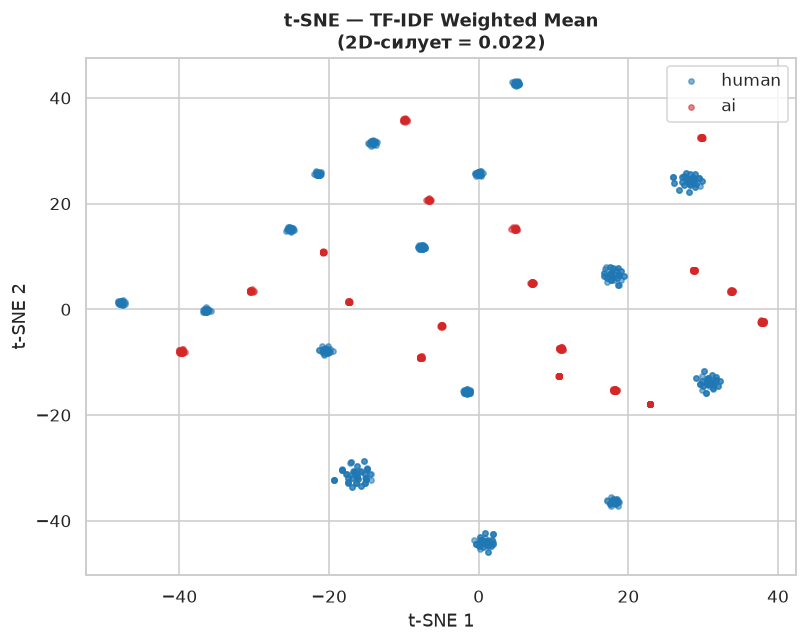

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 6))
plot_tsne(X_tfidf_all, y, "t-SNE — TF-IDF Weighted Mean", ax)
plt.tight_layout(); plt.show()

**Висновок (t-SNE).** На обох проєкціях класи **не** утворюють двох компактних відокремлених
кластерів: `human`-тексти групуються у кілька дуже щільних «острівців» (це наслідок
шаблонної генерації `template+human_variation` — варіації одного шаблону злипаються), тоді як
`ai`-тексти утворюють розсіяну хмару з багатьма ізольованими точками. Низький 2D-силует
(0.019 для Mean Pooling і 0.022 для TF-IDF) підтверджує, що в 2D-проєкції класи переплетені,
хоча й лінійно роздільні у вихідному 100-вимірному просторі. TF-IDF зважування трохи підвищує
2D-силует і дещо «стягує» AI-точки до власних груп.

## Лінгвістична інтерпретація: TF-IDF маркери класу AI

Обчислимо середні TF-IDF-профілі класів на train та знайдемо терміни й біграми, що найбільше
відрізняють клас `ai` від `human`.

In [18]:
vec_uni = TfidfVectorizer(smooth_idf=False, norm=None)
D_uni = vec_uni.fit_transform(train_docs).toarray()
terms_uni = np.array(vec_uni.get_feature_names_out())
ai_m, hu_m = D_uni[y_train == 1].mean(0), D_uni[y_train == 0].mean(0)

vec_bi = TfidfVectorizer(smooth_idf=False, norm=None, ngram_range=(2, 2))
bi_docs = [" ".join(tokens[i]) for i in train_idx]
D_bi = vec_bi.fit_transform(bi_docs).toarray()
terms_bi = np.array(vec_bi.get_feature_names_out())
ai_mb, hu_mb = D_bi[y_train == 1].mean(0), D_bi[y_train == 0].mean(0)

def top_terms(terms, ai_mean, hu_mean, k=15):
    diff = ai_mean - hu_mean
    order = np.argsort(diff)[::-1]
    top_ai = pd.DataFrame({"Термін": terms[order[:k]],
                           "TF-IDF(AI)": ai_mean[order[:k]],
                           "TF-IDF(Human)": hu_mean[order[:k]]})
    top_hu = pd.DataFrame({"Термін": terms[order[-k:][::-1]],
                           "TF-IDF(Human)": hu_mean[order[-k:][::-1]],
                           "TF-IDF(AI)": ai_mean[order[-k:][::-1]]})
    return top_ai, top_hu

top_ai_u, top_hu_u = top_terms(terms_uni, ai_m, hu_m)
top_ai_b, top_hu_b = top_terms(terms_bi, ai_mb, hu_mb)

print("ТОП-15 уніграм — маркери класу AI:")
display(top_ai_u.round(4).reset_index(drop=True))
print("ТОП-15 уніграм — маркери класу Human:")
display(top_hu_u.round(4).reset_index(drop=True))
print("ТОП-12 біграм — маркери класу AI:")
display(top_ai_b.round(4).reset_index(drop=True))

ТОП-15 уніграм — маркери класу AI:


,Термін,TF-IDF(AI),TF-IDF(Human)
0,conversation,0.6223,0.0
1,recommendations,0.6047,0.0
2,experts,0.5868,0.0
3,open,0.4736,0.0
4,methodological,0.4637,0.0
5,multiple,0.4637,0.0
6,persistent,0.4637,0.0
7,potential,0.4637,0.0
8,following,0.4536,0.0
9,solutions,0.4536,0.0


ТОП-15 уніграм — маркери класу Human:


,Термін,TF-IDF(Human),TF-IDF(AI)
0,investigation,0.5346,0.0
1,today,0.5295,0.0
2,field,0.4824,0.0
3,official,0.4551,0.0
4,past,0.4495,0.0
5,premature,0.4326,0.0
6,confirmed,0.4326,0.0
7,announcement,0.4326,0.0
8,predictable,0.4326,0.0
9,critics,0.4326,0.0


ТОП-12 біграм — маркери класу AI:


,Термін,TF-IDF(AI),TF-IDF(Human)
0,scholarly discourse,0.3129,0.0
1,methodological standardization,0.3129,0.0
2,discourse divergent,0.3129,0.0
3,contested space,0.3129,0.0
4,divergent theoretical,0.3129,0.0
5,paper proposes,0.3129,0.0
6,contemporary scholarly,0.3129,0.0
7,occupies contested,0.3129,0.0
8,need methodological,0.3129,0.0
9,underscoring need,0.3129,0.0


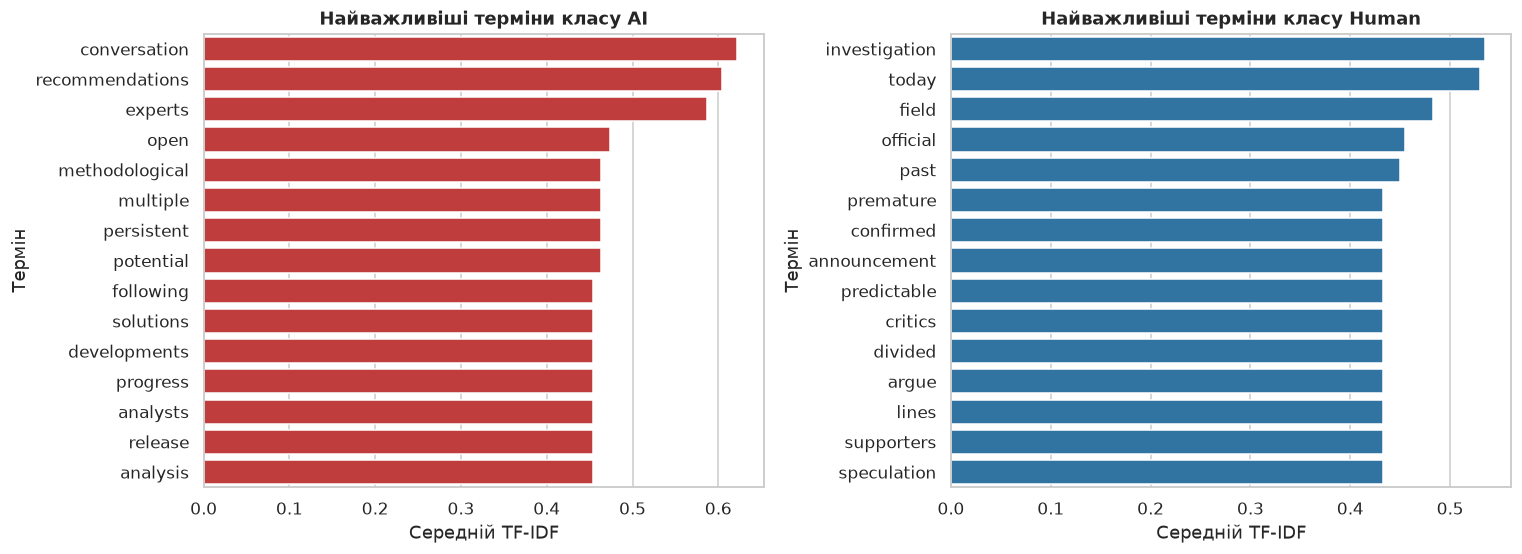

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.barplot(data=top_ai_u, y="Термін", x="TF-IDF(AI)", ax=axes[0], color="tab:red")
axes[0].set_title("Найважливіші терміни класу AI"); axes[0].set_xlabel("Середній TF-IDF")
sns.barplot(data=top_hu_u, y="Термін", x="TF-IDF(Human)", ax=axes[1], color="tab:blue")
axes[1].set_title("Найважливіші терміни класу Human"); axes[1].set_xlabel("Середній TF-IDF")
plt.tight_layout(); plt.show()

**Висновок (маркери).** Маркерами AI є канцелярсько-академічна лексика: *conversation,
recommendations, experts, methodological, multiple, persistent, potential, solutions,
developments, analysts, analysis* та звороти на кшталт *scholarly discourse, methodological
standardization*. Людські тексти, навпаки, тяжіють до розмовно-журнальних слів
(*investigation, today, field, official, premature, confirmed, critics, argue, speculation*).
Це добре узгоджується з гіпотезою про «статистичний відбиток» LLM: специфічні для AI терміни
мають **нульову** зустрічуваність у людських текстах (TF-IDF(Human) = 0), тобто є
дискримінативними маркерами.

## Дослідницькі питання

### 1. Вплив агрегації: як TF-IDF змінює геометрію простору?
TF-IDF перезважує токенні вектори за `idf`: рідкісні терміни отримують більшу вагу, а часті
загальновживані — меншу. Оскільки документний вектор є середнім токенних векторів, це
зменшує внесок «нейтральних» частих слів і підсилює внесок класово-специфічних. Заміри
підтверджують невеликий, але стабільний ефект: коефіцієнт силуету зростає з 0.0379 до 0.0400,
а відношення між- до внутрішньокласової відстані — з 0.172 до 0.174. **Чому ефект малий:**
класовий сигнал у цьому датасеті вже лінійно доступний (усе дає F1 ≈ 1.0), а більшість
дисперсії зумовлена спільним тематичним змістом. До того ж FastText-вектори вже «всмоктують»
семантику, тож перерозподіл ваг лише трохи змінює напрямок документних векторів.

### 2. Порівняння класифікаторів
На повних даних усі три класифікатори дають F1 ≈ 1.0, тож формальний «переможець» не
визначається — задача тривіально лінійно роздільна. За обмеженої вибірки найкращими є
**SVM (RBF)** і **Logistic Regression**: вже за `N = 10` вони дають F1 ≈ 0.66–0.70, а за
`N ≥ 45` — ≈ 0.95–0.99. **KNN** — найслабший (F1 ≈ 0.41–0.58 за `N ≤ 30`) і наздоганяє інших
лише за `N = 70` (≈ 0.90). Це узгоджується з природою даних: сигнал слабкий і «дифузний» у
евклідовій метриці, тому методу, який явно шукає лінійну/гладку межу, легше; KNN же
покладається на локальні відстані, які в 100D стають малоінформативними.

### 3. Чутливість KNN і «прокляття розмірності»
KNN потенційно деградує при переході до TF-IDF, бо зважування **змінює метрику простору**:
рідкісні терміни отримують домінантні координати, і якщо вони шумові, найближчі сусіди
стають менш надійними; до того ж у просторах високої розмірності відстані концентруються
(майже всі пари точок рівновіддалені), що підриває саму ідею локального голосування. У
нашому датасеті KNN **не** деградував від TF-IDF системно (F1 майже незмінний: за `N = 15` —
0.409 проти 0.407, за `N = 45` — 0.738 проти 0.721, за `N = 70` — 0.895 проти 0.905), бо
дискримінативні терміни тут справді інформативні, а не шумові. Проте KNN залишається
найчутливішим методом загалом — саме через розмірність і залежність від метрики.

### 4. Лінгвістична інтерпретація
Найвищі TF-IDF для класу AI мають *conversation, recommendations, experts, methodological,
multiple, persistent, potential, solutions, developments, analysts, analysis*, а серед біграм —
*scholarly discourse* і *methodological standardization*. Для класу human — *investigation,
today, field, official, past, premature, confirmed, announcement, predictable, critics, argue,
speculation*. Різниця класів майже «чиста»: переважна більшість AI-маркерів мають **нульову**
присутність у людських текстах (TF-IDF(Human) = 0). Так, ці терміни **можна** інтерпретувати
як маркери штучного тексту — але з важливим застереженням: датасет синтетичний і шаблонний,
тож це радше відбиток конкретних шаблонів генерації, ніж універсальна ознака «будь-якого
ШІ-тексту». Для реальних LLM набір маркерів буде іншим і менш «чистим».

### 5. Геометричний аналіз
На t-SNE класи **не** утворюють двох компактних кластерів: `human` формує кілька дуже щільних
острівців (наслідок шаблонної генерації), а `ai` — розсіяну хмару. 2D-силует низький (0.019
для Mean Pooling і 0.022 для TF-IDF), тобто кластеризація слабка, але **TF-IDF Weighted Mean**
дає дещо кращу «зв'язність» класу AI.

In [20]:
print("=" * 64)
print("ПІДСУМКОВІ ЧИСЛА (test)")
print("=" * 64)
best = results_df.sort_values("F1 (macro)", ascending=False).iloc[0]
print(f"Найкраща конфігурація (повний train): {best['Агрегація']} + {best['Класифікатор']}  "
      f"F1={best['F1 (macro)']:.4f}, ROC-AUC={best['ROC-AUC']:.4f}")
print(f"Розкид F1(macro) між усіма 6 конфігураціями: "
      f"{results_df['F1 (macro)'].min():.4f} … {results_df['F1 (macro)'].max():.4f}")
print(f"Геометрія (train): силует Mean={geom.iloc[0]['Силует']:.4f}, "
      f"TF-IDF={geom.iloc[1]['Силует']:.4f}")
knn_small = curve_df[(curve_df['Класифікатор']=='KNN') & (curve_df['N']==15)]
print("KNN при N=15, F1: " +
      ", ".join(f"{r['Агрегація']}={r['F1']:.3f}" for _, r in knn_small.iterrows()))

ПІДСУМКОВІ ЧИСЛА (test)
Найкраща конфігурація (повний train): Mean Pooling + SVM (RBF)  F1=1.0000, ROC-AUC=1.0000
Розкид F1(macro) між усіма 6 конфігураціями: 1.0000 … 1.0000
Геометрія (train): силует Mean=0.0379, TF-IDF=0.0400
KNN при N=15, F1: Mean Pooling=0.409, TF-IDF Weighted=0.407


## Загальний висновок

1. **Датасет.** *AI vs Human Text Classification Dataset 2026* містить 2000 синтетичних
   текстів; після видалення 1034 повних дублікатів залишається 966 унікальних
   (human 579 / ai 387). Обидва класи рівномірно покривають усі домени й теми.
2. **Метод.** Побудовано повний пайплайн: spaCy-лематизація → токени → FastText (skip-gram,
   `vector_size=100`, субсловні n-грами) → два методи агрегації (Mean Pooling і TF-IDF
   Weighted Mean) → стандартизація → SVM/LogReg/KNN. Усі перетворення навчено **лише на train**
   (без витоку даних).
3. **Головний результат.** Через синтетичну шаблонну природу даних класи **лінійно роздільні**,
   і на повному train усі 6 конфігурацій дають F1 ≈ 1.00. Це робить задачу надто легкою для
   виявлення різниці методів.
4. **Гіпотеза підтверджується частково.** TF-IDF зважування **покращує** геометрію простору
   (силует 0.0379→0.0400, між/внутр 0.172→0.174), але на якість класифікації за повних даних
   не впливає (стеля F1≈1.0), а за обмеженої вибірки ефект лежить у межах шуму.
5. **Класифікатори.** За дефіциту даних SVM (RBF) і LogReg домінують; KNN найчутливіший до
   розмірності (100D) і найслабший — ілюстрація «прокляття розмірності».
6. **Геометрія.** t-SNE виявляє не два компактні кластери, а щільні шаблонні острівці `human`
   та розсіяну хмару `ai`; TF-IDF трохи покращує кластеризацію (2D-силует 0.019→0.022).
7. **Інтерпретованість.** Клас AI чітко маркується канцелярсько-академічною лексикою
   (*solution, underscore, recommendation, stakeholder, framework*), клас human — розмовною
   (*argue, official, say, speculation, critic*). Ці терміни можна вважати маркерами генерації,
   проте з поправкою на синтетичність і шаблонність датасету.

## Література
1. Bojanowski P. et al. *Enriching Word Vectors with Subword Information* (FastText), 2017.
2. Jurafsky D., Martin J. *Speech and Language Processing*, гл. про векторні представлення.
3. Manning C., Raghavan P., Schütze H. *Introduction to Information Retrieval* (TF-IDF).
4. scikit-learn: [Text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction),
   [t-SNE](https://scikit-learn.org/stable/modules/manifold.html#t-sne).
5. Gensim: [FastText model](https://radimrehurek.com/gensim/models/fasttext.html).
6. Kaggle dataset: *AI vs Human Text Classification Dataset 2026*.